### what is a tool?  
A tools is a python function or an API that LLM can call and understand when needed   
tools are hands and legs of an AI agent through which the agent execute its decision 

We have Built-in Tools like which are "Runnable" object:   
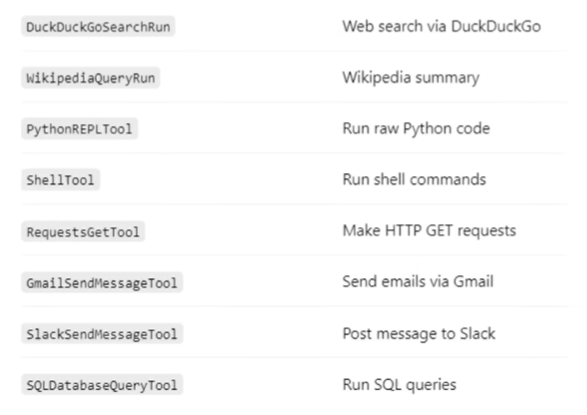

DuckDuckGoSearch for Web Search

In [47]:
from langchain_community.tools import DuckDuckGoSearchRun

search_tool = DuckDuckGoSearchRun()
result = search_tool.invoke("Dharmendra Pradhan response to CJP protest")
print(result)

CJP founder Abhijeet Dipke demands Education Minister Dharmendra Pradhan's resignation during a second protest at Jantar Mantar. The Cockroach Janta Party (CJP) held a protest at Jantar Mantar on Saturday demanding Education Minister Dharmendra Pradhan's resignation as accountability for recent exam paper leaks, as a ... CJP founder Abhijeet Dipke's message to Dharmendra Pradhan amid NEET protest Dipke has been protesting at Jantar Mantar over the alleged NEET paper leak and irregularities in competitive examinations. The spokesperson held a press-conference after the protests wrapped for the day, calling for a response from the govt and said that "Dharmendra Pradhan should resign within 7 days or PM Modi ... Addressing a press conference after the day's protest concluded, the spokesperson demanded a response from the government and said, "Dharmendra Pradhan should resign within 7 days or PM Modi ...


ShellTool for shell commands on the local pc  
(This is risky tho be careful when using)

In [48]:
from langchain_community.tools import ShellTool

shell_tool = ShellTool()
result = shell_tool.invoke("whoami")
print(result)

Executing command:
 whoami
zangetsu\arun



c:\Users\Arun\Documents\Documents\GenAI\env\Lib\site-packages\langchain_community\tools\shell\tool.py:33: UserWarning: The shell tool has no safeguards by default. Use at your own risk.
  warnings.warn(


### Or we can make our own custom tools 

### Method 1: Using "tool" decorator
simple and easy  
but a bit unreliable since we only use type hints instead of type validation and coercion

In [49]:
from langchain_core.tools import tool

In [50]:
@tool
def multiply(a:int, b:int) -> int:
    """Multiply two numbers"""
    return a*b

Dont forget to add
- Type hints and 
- Docstring

In [51]:
result = multiply.invoke({'a':10,'b':20})
result

200

In [52]:
## See properties of tool
print(multiply.name)
print(multiply.description)
print(multiply.args)

multiply
Multiply two numbers
{'a': {'title': 'A', 'type': 'integer'}, 'b': {'title': 'B', 'type': 'integer'}}


The LLM does not see the function or its logic. The LLM only see this JSON schema given below ↓

In [53]:
multiply.args_schema.model_json_schema()

{'description': 'Multiply two numbers',
 'properties': {'a': {'title': 'A', 'type': 'integer'},
  'b': {'title': 'B', 'type': 'integer'}},
 'required': ['a', 'b'],
 'title': 'multiply',
 'type': 'object'}

### Method 2: StructuredTool and Pydantic

In [54]:
from langchain_core.tools import StructuredTool
from pydantic import BaseModel, Field
from typing import Annotated

In [55]:
#Define function
def multiply(a,b):
    return a*b

#Define arguments schema
class multiply_inp(BaseModel):
    a:Annotated[int, Field(..., description="The first number to multiply")]
    b:Annotated[int, Field(..., description="The second number to multiply")]

#Create tool
multiply_tool = StructuredTool.from_function(
    func=multiply, 
    name="multiply", 
    description="Multiply two integers", 
    args_schema=multiply_inp
    )


In [56]:
multiply_tool.invoke(input={'a':10, 'b':20})

200

In [57]:
print(multiply_tool.name)
print(multiply_tool.description)
print(multiply_tool.args_schema.model_json_schema())

multiply
Multiply two integers
{'properties': {'a': {'description': 'The first number to multiply', 'title': 'A', 'type': 'integer'}, 'b': {'description': 'The second number to multiply', 'title': 'B', 'type': 'integer'}}, 'required': ['a', 'b'], 'title': 'multiply_inp', 'type': 'object'}


### Method 3: BaseTool
BaseTool is an abstract base class for all tools in langchain. It defines the interface and core structure that any tool must follow  
"tool" or "StructuredTool" inherits from this base class

### Toolkits
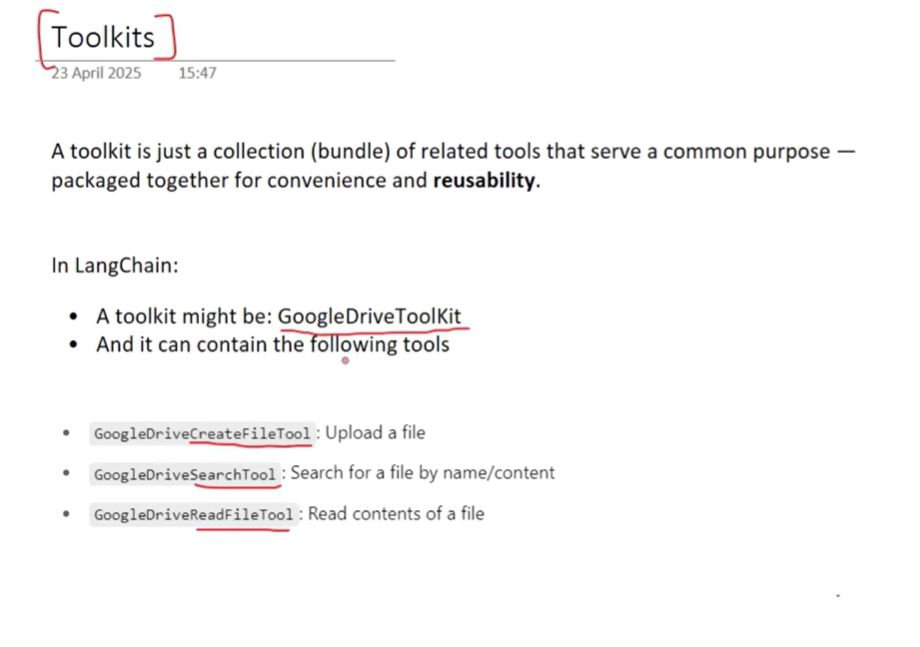

In [59]:
#Define tools
@tool
def add(a:int, b:int) -> int:
    "Add Two Integers"
    return a+b

@tool
def mult(a:int, b:int) -> int:
    "multiply Two Integers"
    return a*b 


#Create toolkit
class MathToolKit:
    def get_tools(self):
        return [add, mult]
    

#instantiate toolkit 
toolkit = MathToolKit()
print(toolkit.get_tools()) #List of tools in the toolkit
for tools in toolkit.get_tools():
    print(tools.name, ", Description:", tools.description)

[StructuredTool(name='add', description='Add Two Integers', args_schema=<class 'langchain_core.utils.pydantic.add'>, func=<function add at 0x0000027A1ADF0360>), StructuredTool(name='mult', description='multiply Two Integers', args_schema=<class 'langchain_core.utils.pydantic.mult'>, func=<function mult at 0x0000027A1ADF2CA0>)]
add , Description: Add Two Integers
mult , Description: multiply Two Integers
